> **NOTICE**
>
> **Warning:** survivorship bias. The stock universe in this case is a list of companies that survived to today. Companies that failed, were delisted or were acquired are missing, so the equity results are likely optimistic. Read them as an upper bound. Membership is point-in-time from the constituents file, but yfinance lacks many delisted names, which drop out of the eligible set, and membership after the last historical date is backfilled with the current list.
>
> **Purpose:** This case shares the strategy logic so you can re-run it on survivorship-free data, for example point-in-time index membership that includes delisted companies and their full price history. Swap the universe and the price loader, keep the rules, and compare the results. The published numbers are for the survivor universe only and must not be read as a realistic estimate.

# Backtest Autopsy #5: S&P 500 top-20 momentum to top-5 hierarchical risk parity, no edge against the index

**Tags:** no edge vs benchmark

## TL;DR

* **Idea.** Each month, take the S&P 500 members at that date, rank them by 105-day momentum (skipping the latest 21 days), keep the top 20, let Hierarchical Risk Parity (HRP) pick and weight the final five, then scale the exposure to a 14% annual volatility target (idle cash earns the overnight rate).
* **Result.** On 100,000 USD of illustrative equity the strategy compounds at **-0.04%** a year (annualised Sharpe -0.15 over a 4.5% cash rate, maximum drawdown -43.1%) against **14.2%** for buy-and-hold SPY (Sharpe 0.54, maximum drawdown -33.7%) and **11.0%** for SPY scaled to the same 14% volatility target (Sharpe 0.50, maximum drawdown -21.0%).
* **Verdict number.** Regressed on SPY the strategy has an annualised alpha of -8.1% (t = -1.63) and a beta of 0.64; against the vol-targeted SPY, the like-for-like benchmark that isolates stock selection, the alpha is -8.4% (t = -1.65). The momentum selection does not beat picking at random among the same names: the strategy's Sharpe sits at the 9th percentile of 100 random-selection runs. Across ten lookback and skip pairs the CAGR runs from -0.04% to 9.5%; none reaches the index.
* **Why it matters.** A strategy can look reasonable on its own equity curve and still be a worse way to hold the index. Always show the benchmark that has the same risk, not only the one that is easiest to beat.
* **And it is flattered.** Even this comparison is optimistic: see the survivorship warning below and section 5.

> Outputs below come from a run on the real data. With `AUTOPSY_SYNTHETIC=1` the notebook runs end to end on a synthetic stock panel with the same schema and will **not** reproduce the failure.

### Prerequisites

* Python 3.10+, `numpy`, `pandas`, `scipy`, `matplotlib`, `pyarrow`, and the shared package `autopsy_common` (`pip install -e ../..`).
* Familiarity with: cross-sectional momentum, Hierarchical Risk Parity (Lopez de Prado, 2016), volatility targeting, point-in-time index membership, and what an alpha regression and a placebo test say.
* Data: your own copies of the daily price panel and the index-membership history described in section 2, in a folder named by `AUTOPSY_DATA_DIR`. No data is shipped with this repository.

## 1. Settings (control panel)

One dictionary holds every governing constant. The values below are the starting point for this case. Change them and re-run the test to see whether the verdict holds; the README lists the implementation notes. Two environment variables select the mode:

* `AUTOPSY_SYNTHETIC=1` builds a synthetic stock panel (same schema, no vendor data).
* `AUTOPSY_DATA_DIR` points at the folder holding your price and membership files.

Design notes:

* **Momentum lookback 105 days** (five months of 21 trading days) with the latest 21 days skipped. The conclusion does not depend on the exact choice (see section 9.3).
* **No regime filter.** An optional index-trend filter is not included.
* **Volatility target 14%** with a correlation-adaptive multiplier (x1.3 when the five names' average pairwise correlation is below 0.2, x0.7 when it is above 0.5), exposure never above 1x.
* **Costs.** The headline is 3 basis points of traded notional. A per-order model with the public broker per-share and minimum-order commissions plus slippage is run as a sensitivity (it is what makes capital matter).
* **Reproducibility switches.** `fallback_order` and `skip_unrankable` only matter in the first rebalances, before enough prices exist to rank names; see section 4.

In [ ]:
from __future__ import annotations

import json
import math
import os
import time
import warnings
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform

from autopsy_common.data import use_synthetic
from autopsy_common.metrics import alpha_beta_regression, block_bootstrap_sharpe
from autopsy_common.perf import drawdown_series, performance_summary, rolling_sharpe, yearly_returns
from autopsy_common.plots import (plot_bar_contribution, plot_capital_sweep, plot_drawdown, plot_equity,
                                  plot_exposure_turnover, plot_monthly_heatmap, plot_return_distribution,
                                  plot_rolling_risk, plot_yearly_bars)
from autopsy_common.schema import check_schema
from autopsy_common.sweep import capital_sweep

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
SYNTHETIC = use_synthetic()
DATA_DIR = Path(os.environ["AUTOPSY_DATA_DIR"]) if os.environ.get("AUTOPSY_DATA_DIR") else None
PRICES_FILE = "sp500_prices.parquet"               # wide daily adjusted closes, one column per ticker plus SPY
MEMBERS_FILE = "sp500_constituents.parquet"        # index membership snapshots: (date, ticker)
RESULTS: Dict[str, Any] = {}

PARAMS: Dict[str, Any] = dict(
    capital=100_000.0,                  # illustrative initial equity in USD (an assumption; see the capital sweep)
    start_date="2018-06-01", end_date="2025-12-31",
    price_start_buffer_days=504,        # calendar days of price history loaded before the start date
    rebalance_days=21,                  # about monthly
    vol_lookback=252,                   # trailing window (trading days) for covariance and volatility
    linkage_method="ward",
    top_n_select=20, top_n_final=5,
    momentum_lookback=105, momentum_skip_days=21,      # lookback in days (see settings notes)
    min_weight=0.05, max_weight=0.40,
    vol_target=0.14, regime_adaptive_vt=True,
    overnight_rate=0.045,
    cost_model="bps", transaction_cost_bps=3.0,         # headline: 3 bp of traded notional
    ibkr_per_share=0.0035, ibkr_min_order=0.35, slippage_bps=3.0,   # per-order sensitivity model
    selection_mode="momentum",          # "random_member" is the placebo in section 9
    fallback_order="sorted",            # fixed order in the rare fallbacks ("set" uses an unordered, hash-dependent order)
    skip_unrankable=True,               # skip leading rebalances until enough names can be ranked
    public_snapshot_end="2019-01-11",   # last snapshot of the public membership file (later dates are reconstructed)
    trading_days=252, n_placebo=100, n_bootstrap=2000, random_seed=11,
)
print(f"mode: {'SYNTHETIC' if SYNTHETIC else 'REAL DATA'} | momentum lookback {PARAMS['momentum_lookback']} "
      f"(skip {PARAMS['momentum_skip_days']}) | top {PARAMS['top_n_select']} -> {PARAMS['top_n_final']}")

mode: REAL DATA | momentum lookback 105 (skip 21) | top 20 -> 5


## 2. Data

### 2.1 Source recipe

| Input | Source | Frequency | Notes |
|---|---|---|---|
| Index membership | Public GitHub repository `fja05680/sp500` ("S&P 500 Historical Components & Changes", CC0), parsed as described below; extended after its last snapshot with today's index list and a table of announced additions and removals | irregular snapshots (dates when membership changed) | **not** a vendor-grade point-in-time record |
| Prices | `yfinance` (Yahoo Finance), adjusted daily closes, downloaded by the reader in batches and cached as one wide table, plus the SPY ETF as the benchmark | daily | delisted names are mostly absent or partial |

**How to rebuild.** Download the public history CSV (one row per snapshot date with a comma-separated ticker list; a ticker with a `-YYYYMM` suffix was removed in that month and is cut off from then), expand it to `(date, ticker)` rows, then append later snapshots from the current index list and the announced changes. For prices, download adjusted closes for every ticker that was ever a member in the window plus `SPY` and store them as a wide table (`date` index, one `float64` column per ticker). The helper below shows the parsing and the **fallback**: when the history ends before the evaluation window, copy today's list forward at quarter starts. This notebook does not download anything.

### 2.2 What the strategy consumes

| Table | Row definition | Key | Columns |
|---|---|---|---|
| membership | one ticker that was in the index on a snapshot date | `(date, ticker)` | `date` (datetime), `ticker` (string) |
| prices | one trading day | `date` (index, unique, ascending) | one `float64` adjusted close per ticker, plus `SPY` |

Nulls: a ticker has no price before it was fetched or after it stopped trading; gaps of up to two days are forward-filled, longer gaps are **not** (filling a gap after a delisting would turn a wipe-out into a flat line). A ticker with fewer than one year of prices is dropped.

In [ ]:
MEMBERS_SCHEMA = {"date": "datetime", "ticker": "string"}
MEMBERS_KEY = ["date", "ticker"]


def parse_constituent_history(raw: pd.DataFrame) -> pd.DataFrame:
    """Expand the public history file (one row per snapshot, comma-separated tickers, optional -YYYYMM removal
    suffix) into (date, ticker) rows. A ticker with a removal suffix stops appearing at the removal date."""
    rows = []
    for _, row in raw.iterrows():
        d = pd.Timestamp(row["date"])
        for tkr_raw in str(row["tickers"]).split(","):
            tkr_raw = tkr_raw.strip()
            if not tkr_raw:
                continue
            tail = tkr_raw.split("-")[-1]
            if "-" in tkr_raw and tail.isdigit() and len(tail) >= 6:
                tkr, removal_str = tkr_raw.rsplit("-", 1)
                removal = (pd.Timestamp(f"{removal_str[:4]}-{removal_str[4:]}-01") if len(removal_str) == 6
                           else pd.Timestamp(f"{removal_str[:4]}-{removal_str[4:6]}-{removal_str[6:]}"))
            else:
                tkr, removal = tkr_raw, None
            rows.append({"date": d, "ticker": tkr, "removal_date": removal})
    df = pd.DataFrame(rows).sort_values(["ticker", "date"])
    out = []
    for tkr, grp in df.groupby("ticker"):
        removal = grp["removal_date"].iloc[0]
        removal = pd.Timestamp("2099-12-31") if pd.isna(removal) else removal
        out.extend({"date": d, "ticker": tkr} for d in grp["date"].sort_values() if d < removal)
    return pd.DataFrame(out).drop_duplicates().sort_values("date").reset_index(drop=True)


def backfill_from_current_list(history: pd.DataFrame, current_tickers: List[str], today: pd.Timestamp) -> pd.DataFrame:
    """Fallback when the history ends early: copy TODAY's list forward, one snapshot per
    quarter start, after the last historical date. Every name in today's list is thereby treated as a member for
    the whole of that period, whether or not it was."""
    last = history["date"].max()
    fill_dates = pd.date_range(last + pd.Timedelta(days=1), today, freq="QS")
    if len(fill_dates) == 0:
        fill_dates = [today]
    filled = pd.DataFrame([{"date": d, "ticker": t} for d in fill_dates for t in current_tickers])
    return pd.concat([history, filled], ignore_index=True).sort_values("date").drop_duplicates().reset_index(drop=True)


def synthetic_stock_data(n_tickers: int = 90, n_days: int = 2300, seed: int = 3, start: str = "2017-01-13"):
    """Synthetic daily closes and membership snapshots (some names enter late and some leave early, so the
    delisting path is exercised). Driftless random walks: no momentum edge by construction."""
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(start, periods=n_days, name="Date")
    common = rng.normal(0.0004, 0.008, n_days)
    cols = {}
    for i in range(n_tickers):
        px = 50.0 * np.exp(np.cumsum(0.9 * rng.normal(0.0, 0.016, n_days) + common))
        s = pd.Series(px, index=dates)
        life_start = int(rng.integers(0, n_days // 4)) if i % 5 == 0 else 0
        life_end = int(rng.integers(n_days // 2, n_days)) if i % 7 == 0 else n_days
        s.iloc[:life_start] = np.nan
        s.iloc[life_end:] = np.nan
        cols[f"S{i:03d}"] = s
    cols["SPY"] = pd.Series(100.0 * np.exp(np.cumsum(common + rng.normal(0.0, 0.002, n_days))), index=dates)
    prices = pd.DataFrame(cols)
    snaps = pd.date_range(dates[0], dates[-1], freq="MS")
    rows = []
    for d in snaps:
        live = [c for c in prices.columns if c != "SPY" and pd.notna(prices[c].asof(d))]
        rows.extend({"date": d, "ticker": t} for t in live)
    return prices, pd.DataFrame(rows)


def load_inputs(p: Dict[str, Any]):
    if SYNTHETIC:
        prices, members = synthetic_stock_data()
    else:
        if DATA_DIR is None:
            raise RuntimeError("Set AUTOPSY_SYNTHETIC=1, or AUTOPSY_DATA_DIR to the folder with the price and membership files.")
        prices = pd.read_parquet(DATA_DIR / PRICES_FILE)
        members = pd.read_parquet(DATA_DIR / MEMBERS_FILE)
    members = members[list(MEMBERS_SCHEMA)].copy()
    members["date"] = pd.to_datetime(members["date"])
    members = members.sort_values(MEMBERS_KEY, kind="stable").reset_index(drop=True)
    check_schema(members, MEMBERS_SCHEMA, MEMBERS_KEY)
    prices = prices.sort_index()
    return prices, members


PRICES_RAW, CONSTITUENTS = load_inputs(PARAMS)
print("schema check passed (membership):", True)
print("membership: key unique:", not bool(CONSTITUENTS.duplicated(MEMBERS_KEY).any()))
print("prices: index unique:", bool(PRICES_RAW.index.is_unique), "| sorted:", bool(PRICES_RAW.index.is_monotonic_increasing),
      "| all float64:", bool((PRICES_RAW.dtypes == "float64").all()), "| columns unique:", bool(PRICES_RAW.columns.is_unique),
      "| SPY present:", "SPY" in PRICES_RAW.columns)
print("prices: no non-positive values:", bool((PRICES_RAW.fillna(1.0) > 0).all().all()))

schema check passed (membership): True
membership: key unique: True
prices: index unique: True | sorted: True | all float64: True | columns unique: True | SPY present: True
prices: no non-positive values: True


### 2.3 Preparing the panel

The loaded window starts 504 calendar days before the start date (so the 252-day windows are filled at the first rebalance) and ends at the end date. Gaps of up to two days are forward-filled, SPY is split off as the benchmark, and tickers with fewer than 252 observations are dropped. Membership snapshots become a lookup from date to the set of members.

In [ ]:
def prepare_prices(prices_raw: pd.DataFrame, p: Dict[str, Any]) -> Tuple[pd.DataFrame, pd.Series]:
    """Slice the loaded window, split off SPY and keep tickers with at least `vol_lookback` observations."""
    start = pd.Timestamp(p["start_date"]) - pd.DateOffset(days=int(p["price_start_buffer_days"]))
    end = pd.Timestamp(p["end_date"])
    px = prices_raw.loc[start:end].ffill(limit=2)          # bridge one- and two-day gaps only
    bench = px["SPY"].dropna()
    px = px.drop(columns=["SPY"])
    keep = [c for c in px.columns if px[c].notna().sum() >= int(p["vol_lookback"])]
    return px[keep], bench


PRICES, SPY = prepare_prices(PRICES_RAW, PARAMS)
MEMBER_SETS = {d: frozenset(g) for d, g in CONSTITUENTS.groupby("date")["ticker"]}
print("panel prepared: history filter applied, SPY split off as the benchmark:", bool("SPY" not in PRICES.columns and len(SPY) > 0))

panel prepared: history filter applied, SPY split off as the benchmark: True


## 3. Step 1: HRP weights

Hierarchical Risk Parity (Lopez de Prado, 2016) allocates without inverting a covariance matrix: (1) cluster assets by the distance `sqrt(0.5 (1 - correlation))` with Ward linkage, (2) order them along the dendrogram so similar assets are adjacent (**quasi-diagonalisation**), (3) split the ordered list in half recursively and give each half a share of weight inversely proportional to its variance (the variance of the inverse-variance portfolio inside the half). The strategy runs HRP on the **20** momentum leaders and keeps the **five** with the largest weights, re-normalised and clipped to 5% to 40% each.

What can go wrong: the recursive split is by *position* in the ordered list, not by cluster boundary, and the weight of a name depends on where the dendrogram happens to place it; with 20 candidates and a 252-day window the estimated correlation matrix is noisy.

In [ ]:
def compute_hrp_weights(returns: pd.DataFrame, linkage_method: str = "ward", min_w: float = 0.0, max_w: float = 1.0) -> pd.Series:
    n = returns.shape[1]
    tickers = returns.columns.tolist()
    if n <= 1:
        return pd.Series({tickers[0]: 1.0})
    if n == 2:
        inv_var = 1.0 / returns.var().replace(0, np.nan)
        return (inv_var / inv_var.sum()).clip(min_w, max_w)
    corr = returns.corr().values
    dist = np.sqrt(0.5 * (1.0 - corr))
    np.fill_diagonal(dist, 0.0)
    try:
        link = linkage(squareform(dist, checks=False), method=linkage_method)
    except Exception:
        link = linkage(squareform(dist, checks=False), method="single")
    order = _quasi_diag(link)
    cov_sorted = returns.cov().values[np.ix_(order, order)]
    w = pd.Series(_recursive_bisection(cov_sorted), index=[tickers[i] for i in order]).reindex(tickers, fill_value=0.0)
    w = (w / w.sum()).clip(min_w, max_w)
    return w / w.sum()


def _quasi_diag(link: np.ndarray) -> List[int]:
    n = link.shape[0] + 1

    def walk(node: int) -> List[int]:
        if node < n:
            return [int(node)]
        row = int(node - n)
        return walk(int(link[row, 0])) + walk(int(link[row, 1]))
    return walk(2 * n - 2)


def _cluster_var(cov_slice: np.ndarray) -> float:
    """Variance of the inverse-variance-weighted portfolio inside a cluster."""
    if cov_slice.shape[0] == 1:
        return max(float(cov_slice[0, 0]), 1e-12)
    diag = np.diag(cov_slice)
    inv = 1.0 / np.where(diag > 1e-12, diag, 1e-12)
    w = inv / inv.sum()
    return max(float(w @ cov_slice @ w), 1e-12)


def _recursive_bisection(cov: np.ndarray) -> np.ndarray:
    n = cov.shape[0]
    if n == 1:
        return np.array([1.0])
    split = n // 2
    left, right = cov[:split, :split], cov[split:, split:]
    a_left, a_right = 1.0 / max(_cluster_var(left), 1e-12), 1.0 / max(_cluster_var(right), 1e-12)
    alloc_left = a_left / (a_left + a_right)
    w = np.concatenate([alloc_left * _recursive_bisection(left), (1.0 - alloc_left) * _recursive_bisection(right)])
    return w / w.sum()


# a tiny check on a known structure: two independent, equal-volatility groups get equal total weight
_rng = np.random.default_rng(0)
_f1, _f2 = _rng.normal(size=500), _rng.normal(size=500)
_toy = pd.DataFrame({"a": _f1 + 0.1 * _rng.normal(size=500), "b": _f1 + 0.1 * _rng.normal(size=500),
                     "c": _f2 + 0.1 * _rng.normal(size=500), "d": _f2 + 0.1 * _rng.normal(size=500)})
_w = compute_hrp_weights(_toy)
print("toy HRP weights sum to 1:", bool(abs(_w.sum() - 1.0) < 1e-9), "| group weights:", {"ab": round(float(_w[["a", "b"]].sum()), 2), "cd": round(float(_w[["c", "d"]].sum()), 2)})

toy HRP weights sum to 1: True | group weights: {'ab': 0.46, 'cd': 0.54}


## 4. Step 2: the monthly engine

At each rebalance (every 21 trading days, from the first date after the start date with a full one-year window):

1. **Universe.** The members of the index at that date that have prices.
2. **Momentum.** For each name, the average of a five-day window ending 21 days ago divided by the average of a five-day window ending `21 + 105` days ago, minus one (the five-day averages make the signal robust to a single missing price). Keep the top 20.
3. **HRP** on those 20 (a name needs prices on at least 80% of the 252-day window to enter; fewer than two such names falls back to equal weights on the top momentum names), keep the five largest weights, clip to 5% to 40%, re-normalise.
4. **Volatility target.** Compute the five names' trailing volatility; scale weights by `min(target / realised, 1)`, with the target multiplied by 1.3 or 0.7 by the average pairwise correlation. The unused weight is cash and earns the overnight rate.
5. **Costs** on the traded notional against the previous *unscaled* weights.
6. **Hold** until the next rebalance, applying daily returns. A holding that leaves the index is sold at the next close and its weight is spread over the survivors without raising total exposure.

**Warm-up rule.** A rebalance needs enough names with computable momentum. An unordered fallback, when no names can be ranked, would equal-weight the first five names of an unordered *set* (an order that changes with Python's hash seed). Here a rebalance with fewer than 20 rankable names is **skipped** until the lookback is filled (`skip_unrankable`), and the few remaining fallbacks use a sorted order, so the result is deterministic.

In [ ]:
def average_pairwise_correlation(prices: pd.DataFrame, tickers: List[str], idx: int, lb_days: int = 252) -> Optional[float]:
    if idx < 252 or len(tickers) < 2:
        return None
    rets = prices[tickers].iloc[max(0, idx - lb_days):idx].pct_change().dropna(how="all")
    if rets.shape[0] < 63:
        return None
    corr = rets.corr().values
    n = corr.shape[0]
    tril = corr[np.tril_indices(n, -1)]
    return float(np.mean(tril)) if len(tril) else 0.0


def trade_cost(old_w: Optional[pd.Series], new_w: pd.Series, prices_now: pd.Series, equity: float, turnover: float, p: Dict[str, Any]) -> float:
    if p["cost_model"] == "bps":
        return 0.0 if old_w is None else equity * p["transaction_cost_bps"] / 10_000.0 * turnover
    if p["cost_model"] != "ibkr":
        raise ValueError("cost_model must be 'bps' or 'ibkr'")
    old = old_w if old_w is not None else pd.Series(dtype=float)
    names = sorted(set(old.index) | set(new_w.index))
    old, new = old.reindex(names).fillna(0.0), new_w.reindex(names).fillna(0.0)
    total = 0.0
    for t in names:
        notional = abs(float(new[t] - old[t])) * equity
        if notional < 1.0:
            continue
        px = prices_now.get(t, np.nan)
        if not np.isfinite(px) or px <= 0:
            continue
        total += max(p["ibkr_min_order"], p["ibkr_per_share"] * notional / float(px)) + notional * p["slippage_bps"] / 10_000.0
    return float(total)


def run_backtest(prices: pd.DataFrame, member_sets_: Dict[pd.Timestamp, frozenset], p: Dict[str, Any],
                 rng: Optional[np.random.Generator] = None) -> Dict[str, Any]:
    """Monthly top-N momentum -> HRP top-K with a volatility target. Returns daily equity, weights and exposure."""
    ic, rb_days, vol_lb = float(p["capital"]), int(p["rebalance_days"]), int(p["vol_lookback"])
    top_sel, top_fin = int(p["top_n_select"]), int(p["top_n_final"])
    mom_lb, mom_skip, rf = int(p["momentum_lookback"]), int(p["momentum_skip_days"]), float(p["overnight_rate"])
    returns = prices.pct_change()                     # not dropna-d: delisted names keep NaN tails
    dates = prices.index.tolist()
    start_idx = max(vol_lb, int(prices.index.searchsorted(pd.Timestamp(p["start_date"]))))
    rebalance_indices = list(range(start_idx, len(dates), rb_days))
    if rebalance_indices[-1] != len(dates) - 1:
        rebalance_indices.append(len(dates) - 1)
    mdates = pd.DatetimeIndex(sorted(member_sets_))

    def live_members(d: pd.Timestamp) -> frozenset:
        i = mdates.searchsorted(d, side="right") - 1
        return member_sets_[mdates[i]] if i >= 0 else frozenset()

    equity, current_w = ic, None
    eq_rows, w_rows = [], []
    for ri, rebal_idx in enumerate(rebalance_indices):
        rebal_date = dates[rebal_idx]
        cash_weight = 0.0
        sp_set = live_members(rebal_date)
        avail = [t for t in sp_set if t in prices.columns]
        if p["fallback_order"] == "sorted":
            avail = sorted(avail)
        if len(avail) < top_sel:
            avail = (sorted(sp_set) if p["fallback_order"] == "sorted" else list(sp_set))[:top_sel]
        lb_start = max(0, rebal_idx - vol_lb)
        sl = prices.iloc[lb_start:rebal_idx]
        if sl.shape[0] < mom_lb:
            top_tickers = avail[:top_fin]
            new_w = pd.Series(1.0 / len(top_tickers), index=top_tickers)
        else:
            n_bars = len(sl)
            win = 5
            end_bar, start_bar = min(mom_skip, n_bars - 1), min(mom_lb + mom_skip, n_bars - 1)
            ps = sl[[t for t in avail if t in sl.columns]].ffill(limit=2)
            end_hi, end_lo = -end_bar, -min(end_bar + win, n_bars)
            start_hi, start_lo = -start_bar, -min(start_bar + win, n_bars)
            end_px = ps.iloc[end_lo:end_hi if end_hi < 0 else None].mean(axis=0)
            start_px = ps.iloc[start_lo:start_hi].mean(axis=0)
            mom = (end_px / start_px - 1).dropna()
            if p["skip_unrankable"] and len(mom) < top_sel and not eq_rows:
                continue                                  # leading rebalance with too few rankable names: skip
            if len(mom) == 0:
                top_tickers = avail[:top_fin]
            elif p["selection_mode"] == "random_member" and rng is not None:
                pool = sorted(mom.index)
                k = min(top_sel, len(pool))
                top_tickers = list(rng.choice(pool, size=k, replace=False))
            elif len(mom) < top_sel:
                top_tickers = list(mom.nlargest(len(mom)).index)
            else:
                top_tickers = list(mom.nlargest(top_sel).index)
            lb_ret = returns.iloc[lb_start:rebal_idx]
            final = top_tickers[:top_fin]
            min_bars = max(int(0.8 * lb_ret.shape[0]), 2)
            valid = [t for t in top_tickers if t in lb_ret.columns and lb_ret[t].notna().sum() >= min_bars]
            if len(valid) < 2:
                final = (valid or top_tickers)[:top_fin]
                new_w = pd.Series(1.0 / len(final), index=final)
            else:
                sub = lb_ret[valid].ffill(limit=2).fillna(0.0)
                if sub.shape[1] < 2 or sub.shape[0] < 20:
                    final = valid[:top_fin]
                    new_w = pd.Series(1.0 / len(final), index=final)
                else:
                    try:
                        hrp = compute_hrp_weights(sub, linkage_method=p["linkage_method"], min_w=0.0, max_w=1.0)
                        fw = hrp.nlargest(min(top_fin, len(hrp)))
                        fw = fw / fw.sum()
                        fw = fw.clip(lower=p["min_weight"], upper=p["max_weight"])
                        new_w = fw / fw.sum()
                    except Exception:
                        final = valid[:top_fin]
                        new_w = pd.Series(1.0 / len(final), index=final)
            vt = p["vol_target"]
            if p["regime_adaptive_vt"] and vt > 0 and len(new_w) >= 3:
                ac = average_pairwise_correlation(prices, list(new_w.index), rebal_idx)
                if ac is not None:
                    vt = vt * 1.3 if ac < 0.2 else (vt * 0.7 if ac > 0.5 else vt)
            if vt > 0 and len(new_w) >= 2:
                sv = lb_ret[[t for t in new_w.index if t in lb_ret.columns]].dropna()
                if sv.shape[1] >= 2 and sv.shape[0] > 20:
                    wa = new_w[sv.columns]
                    wa = wa / wa.sum()
                    realised = (sv * wa.values).sum(axis=1).std() * np.sqrt(252)
                    if realised > 0.001:
                        new_w = new_w * min(vt / realised, 1.0)
            cash_weight = max(0.0, 1.0 - new_w.sum())
        unscaled = new_w / new_w.sum() if new_w.sum() > 0 else new_w
        turnover = 0.0
        if current_w is not None:
            names = sorted(set(current_w.index) | set(unscaled.index))
            turnover = float(np.sum(np.abs(unscaled.reindex(names).fillna(0.0).values - current_w.reindex(names).fillna(0.0).values)) / 2.0)
        cost = trade_cost(current_w, new_w, prices.iloc[rebal_idx], equity, turnover, p)
        if cost > 0:
            equity = max(0.01, equity - cost)
        next_idx = rebalance_indices[ri + 1] if ri + 1 < len(rebalance_indices) else len(dates) - 1
        fwd = returns.iloc[rebal_idx + 1:next_idx + 1]
        if not fwd.empty:
            aw, ac_ = new_w.copy(), float(cash_weight)
            gross0 = float(aw.sum())
            for k in range(len(fwd)):
                d = fwd.index[k]
                dead = [t for t in aw.index if t not in live_members(d)]
                if dead:
                    freed = sum(float(aw.get(t, 0.0)) for t in dead)
                    aw = aw.drop(dead, errors="ignore")
                    if len(aw) > 0 and aw.sum() > 0:
                        cg = float(aw.sum())
                        aw = aw * (min(gross0, cg + freed) / cg)
                    ac_ = max(0.0, ac_ + freed - (float(aw.sum()) - (gross0 - freed)))
                    gross0 = float(aw.sum())
                tk = [t for t in aw.index if t in fwd.columns]
                eq_r = float(np.nansum(fwd.iloc[k][tk].values * aw[tk].values)) if tk else 0.0
                r = eq_r + ac_ * (rf / 252.0)
                equity *= (1.0 + r)
                eq_rows.append({"date": d, "equity": equity, "gross": float(aw.sum())})
        w_rows.append({"date": rebal_date, "turnover": turnover, "cost": cost, "gross_exposure": float(new_w.sum()),
                       "n_selected": int(len(new_w)), "holdings": list(new_w.index)})
        current_w = unscaled
    eq = pd.DataFrame(eq_rows).set_index("date")
    return {"equity": eq, "weights": pd.DataFrame(w_rows).set_index("date")}


def benchmarks(spy: pd.Series, dates: pd.DatetimeIndex, p: Dict[str, Any]) -> Tuple[pd.Series, pd.Series, pd.Series]:
    """Buy-and-hold SPY and SPY scaled to the same volatility target (63-day trailing volatility, one-day lag,
    exposure at most 1x, the rest in cash at the overnight rate), both aligned to the strategy's dates."""
    r = spy.pct_change()
    roll = r.rolling(63).std() * np.sqrt(252)
    scale = (p["vol_target"] / roll).clip(upper=1.0).shift(1).fillna(0.0)
    vt = r * scale + (1.0 - scale).clip(lower=0.0) * (p["overnight_rate"] / 252.0)
    return r.reindex(dates), vt.reindex(dates), scale.reindex(dates)


t0 = time.time()
BT = run_backtest(PRICES, MEMBER_SETS, PARAMS)
EQ = BT["equity"]
print(f"backtest done in {time.time() - t0:.1f}s | rebalances: {len(BT['weights'])} | holdings per rebalance (max): {int(BT['weights']['n_selected'].max())}")

backtest done in 1.9s | rebalances: 88 | holdings per rebalance (max): 5


## 5. How much of the universe can actually be traded? A survivorship measurement

Before reading any result, measure the data. For every rebalance date the membership table says which stocks were in the index; the price table says which of them have a price that day. The gap is not random: names that were later removed from the index (delisted, acquired, demoted) are the ones a free price source drops. Per rebalance date:

* **coverage of the survivors**: among members that are still in the latest membership snapshot, the share with a price that day;
* **coverage of the removed**: among members that were later removed, the share with a price that day;
* **share of members that were later removed**: how many failures the membership table still contains at all.

A large gap between the first two means every ranking quietly excludes the losers. A fourth measurement: the share of rebalance dates that fall after the public membership file's last snapshot, where membership is reconstructed rather than observed.

mean share of index members with a price on the rebalance date: 89.1% (lowest 83.0%)
members still in the latest snapshot: 94.2% have a price | members later removed: 58.0% have a price
share of the membership table made of names later removed: 12.8% on average
share of rebalance dates after the public membership file's last snapshot (reconstructed membership): 95.5%


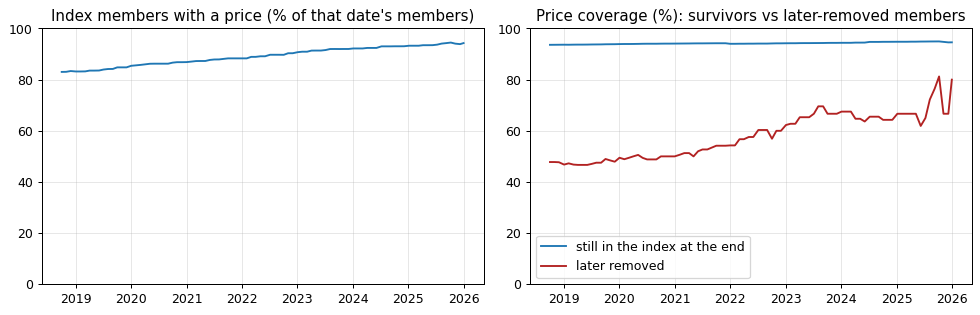

In [ ]:
member_dates = pd.DatetimeIndex(sorted(MEMBER_SETS))
final_members = MEMBER_SETS[member_dates[-1]]
has_price = PRICES.notna()
rows = []
for d in BT["weights"].index:
    i = member_dates.searchsorted(d, side="right") - 1
    m = MEMBER_SETS[member_dates[i]] if i >= 0 else frozenset()
    ok = {t: (t in has_price.columns and bool(has_price.at[d, t])) for t in m}
    surv = [t for t in m if t in final_members]
    gone = [t for t in m if t not in final_members]
    rows.append({"date": d, "coverage": float(np.mean(list(ok.values()))) if ok else np.nan,
                 "coverage_survivors": float(np.mean([ok[t] for t in surv])) if surv else np.nan,
                 "coverage_removed": float(np.mean([ok[t] for t in gone])) if gone else np.nan,
                 "share_removed": len(gone) / max(len(m), 1)})
cov = pd.DataFrame(rows).set_index("date")
snapshot_end = pd.Timestamp(PARAMS["public_snapshot_end"])
share_reconstructed = float((cov.index > snapshot_end).mean())
print(f"mean share of index members with a price on the rebalance date: {cov['coverage'].mean():.1%} (lowest {cov['coverage'].min():.1%})")
print(f"members still in the latest snapshot: {cov['coverage_survivors'].mean():.1%} have a price | members later removed: "
      f"{cov['coverage_removed'].mean():.1%} have a price")
print(f"share of the membership table made of names later removed: {cov['share_removed'].mean():.1%} on average")
print(f"share of rebalance dates after the public membership file's last snapshot (reconstructed membership): {share_reconstructed:.1%}")
RESULTS.update({"coverage_mean": float(cov["coverage"].mean()), "coverage_min": float(cov["coverage"].min()),
                "coverage_survivors": float(cov["coverage_survivors"].mean()), "coverage_removed": float(cov["coverage_removed"].mean()),
                "share_removed": float(cov["share_removed"].mean()), "share_reconstructed": share_reconstructed})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(cov["coverage"] * 100)
axes[0].set_title("Index members with a price (% of that date's members)")
axes[0].set_ylim(0, 100)
axes[1].plot(cov["coverage_survivors"] * 100, label="still in the index at the end")
axes[1].plot(cov["coverage_removed"] * 100, color="firebrick", label="later removed")
axes[1].set_title("Price coverage (%): survivors vs later-removed members")
axes[1].set_ylim(0, 100)
axes[1].legend()
fig.tight_layout()
plt.show()

## 6. Results and metrics against two benchmarks

The case defines two benchmarks and this notebook keeps both:

* **SPY buy and hold**: the easiest question, "did I beat the index?".
* **SPY volatility-targeted to the same 14%**: scaled each day by `min(14% / trailing 63-day volatility, 1)` with the remainder in cash. It is the **like-for-like** benchmark: if the strategy's edge came only from running less risk, this series gets the same edge for free, so what remains after it is the stock selection.

Returns are daily and net of costs. Sharpe ratios subtract the constant 4.5% cash rate (`risk_free` below). The CAGR uses calendar years.

In [ ]:
ppy = int(PARAMS["trading_days"])
rf_ann = float(PARAMS["overnight_rate"])
dates_s = EQ.index
strat = (EQ["equity"] / EQ["equity"].shift(1).fillna(float(PARAMS["capital"])) - 1.0)
spy_ret, vt_ret, vt_scale = benchmarks(SPY, dates_s, PARAMS)
spy_ret, vt_ret = spy_ret.fillna(0.0), vt_ret.fillna(0.0)


def calendar_cagr(r: pd.Series) -> float:
    eq = (1.0 + r).cumprod()
    years = max((r.index[-1] - r.index[0]).days, 1) / 365.25
    return float(eq.iloc[-1] ** (1.0 / max(years, 0.02)) - 1.0)


sm = {n: performance_summary(r, periods_per_year=ppy, risk_free=rf_ann) for n, r in
      {"strategy": strat, "SPY": spy_ret, "SPY vol-targeted": vt_ret}.items()}
tbl = pd.DataFrame(sm)
tbl.loc["cagr_calendar"] = [calendar_cagr(r) for r in (strat, spy_ret, vt_ret)]
tbl.loc["avg_exposure"] = [float(EQ["gross"].mean()), 1.0, float(vt_scale.mean())]
display(tbl.loc[["cagr_calendar", "total_return", "ann_vol", "sharpe", "sortino", "calmar", "max_drawdown", "max_drawdown_duration",
                 "hit_rate", "profit_factor", "skew", "kurtosis", "var_95", "cvar_95", "best_month", "worst_month"]].round(4))

reg_spy = alpha_beta_regression(strat, spy_ret, periods_per_year=ppy)
reg_vt = alpha_beta_regression(strat, vt_ret, periods_per_year=ppy)
reg = pd.DataFrame({"vs SPY": reg_spy, "vs vol-targeted SPY": reg_vt})
display(reg.round(4))
blk_s = block_bootstrap_sharpe(strat, block=21, n_boot=int(PARAMS["n_bootstrap"]), seed=int(PARAMS["random_seed"]))
print(f"block-bootstrap 90% interval of the strategy's Sharpe (excess of nothing, 21-day blocks): [{blk_s['lo']:.2f}, {blk_s['hi']:.2f}]")

# paired block bootstrap of the Sharpe difference against each benchmark
def paired_sharpe_diff(a: pd.Series, b: pd.Series, block: int = 21, n_boot: int = 2000, seed: int = 11) -> Dict[str, float]:
    rng = np.random.default_rng(seed)
    x, y = a.to_numpy(), b.to_numpy()
    n = len(x)
    nb_ = int(np.ceil(n / block))
    daily_rf = rf_ann / ppy
    out = np.empty(n_boot)
    for i in range(n_boot):
        s = rng.integers(0, n - block + 1, nb_)
        idx = (s[:, None] + np.arange(block)[None, :]).ravel()[:n]
        xa, ya = x[idx] - daily_rf, y[idx] - daily_rf
        out[i] = np.sqrt(ppy) * (xa.mean() / xa.std(ddof=1) - ya.mean() / ya.std(ddof=1))
    return {"lo": float(np.quantile(out, 0.05)), "hi": float(np.quantile(out, 0.95)), "share_positive": float((out > 0).mean())}


d_spy = paired_sharpe_diff(strat, spy_ret, seed=int(PARAMS["random_seed"]), n_boot=int(PARAMS["n_bootstrap"]))
d_vt = paired_sharpe_diff(strat, vt_ret, seed=int(PARAMS["random_seed"]), n_boot=int(PARAMS["n_bootstrap"]))
print(f"Sharpe difference vs SPY: 90% interval [{d_spy['lo']:.2f}, {d_spy['hi']:.2f}], share of resamples > 0: {d_spy['share_positive']:.2f}")
print(f"Sharpe difference vs vol-targeted SPY: 90% interval [{d_vt['lo']:.2f}, {d_vt['hi']:.2f}], share of resamples > 0: {d_vt['share_positive']:.2f}")
cap = float(PARAMS["capital"])
RESULTS.update({
    "s_cagr": float(tbl.loc["cagr_calendar", "strategy"]), "spy_cagr": float(tbl.loc["cagr_calendar", "SPY"]), "vt_cagr": float(tbl.loc["cagr_calendar", "SPY vol-targeted"]),
    "s_sharpe": float(tbl.loc["sharpe", "strategy"]), "spy_sharpe": float(tbl.loc["sharpe", "SPY"]), "vt_sharpe": float(tbl.loc["sharpe", "SPY vol-targeted"]),
    "s_mdd": float(tbl.loc["max_drawdown", "strategy"]), "spy_mdd": float(tbl.loc["max_drawdown", "SPY"]), "vt_mdd": float(tbl.loc["max_drawdown", "SPY vol-targeted"]),
    "s_total": float(tbl.loc["total_return", "strategy"]), "spy_total": float(tbl.loc["total_return", "SPY"]), "vt_total": float(tbl.loc["total_return", "SPY vol-targeted"]),
    "s_vol": float(tbl.loc["ann_vol", "strategy"]), "spy_vol": float(tbl.loc["ann_vol", "SPY"]), "vt_vol": float(tbl.loc["ann_vol", "SPY vol-targeted"]),
    "s_final_usd": float(EQ["equity"].iloc[-1]), "spy_final_usd": float(cap * (1 + spy_ret).prod()), "vt_final_usd": float(cap * (1 + vt_ret).prod()),
    "alpha_spy": float(reg_spy["alpha_ann"]), "t_alpha_spy": float(reg_spy["t_alpha"]), "beta_spy": float(reg_spy["beta"]),
    "ir_spy": float(reg_spy["information_ratio"]), "te_spy": float(reg_spy["tracking_error_ann"]),
    "alpha_vt": float(reg_vt["alpha_ann"]), "t_alpha_vt": float(reg_vt["t_alpha"]), "beta_vt": float(reg_vt["beta"]),
    "ir_vt": float(reg_vt["information_ratio"]), "r2_spy": float(reg_spy["r_squared"]),
    "sharpe_ci_lo": float(blk_s["lo"]), "sharpe_ci_hi": float(blk_s["hi"]),
    "dsharpe_spy_lo": d_spy["lo"], "dsharpe_spy_hi": d_spy["hi"], "dsharpe_spy_pos": d_spy["share_positive"],
    "dsharpe_vt_lo": d_vt["lo"], "dsharpe_vt_hi": d_vt["hi"], "dsharpe_vt_pos": d_vt["share_positive"],
    "avg_turnover": float(BT["weights"]["turnover"].mean()), "avg_gross": float(EQ["gross"].mean()),
    "n_rebalances": int(len(BT["weights"])), "total_cost_usd": float(BT["weights"]["cost"].sum()),
})

,strategy,SPY,SPY vol-targeted
cagr_calendar,-0.0004,0.1418,0.1102
total_return,-0.0031,1.6143,1.1336
ann_vol,0.1842,0.1994,0.1394
sharpe,-0.1538,0.5410,0.4991
sortino,0.1068,0.9412,1.0490
calmar,-0.0010,0.4216,0.5254
max_drawdown,-0.4311,-0.3372,-0.2103
max_drawdown_duration,1115.0000,488.0000,383.0000
hit_rate,0.5318,0.5527,0.5543
profit_factor,1.0171,1.1586,1.1559


,vs SPY,vs vol-targeted SPY
alpha_per_period,-0.0003,-0.0003
alpha_ann,-0.0810,-0.0843
beta,0.6387,0.8813
t_alpha,-1.6343,-1.6490
r_squared,0.4783,0.4449
tracking_error_ann,0.1513,0.1382
information_ratio,-0.9003,-0.7083


block-bootstrap 90% interval of the strategy's Sharpe (excess of nothing, 21-day blocks): [-0.43, 0.79]
Sharpe difference vs SPY: 90% interval [-1.13, -0.25], share of resamples > 0: 0.00
Sharpe difference vs vol-targeted SPY: 90% interval [-1.09, -0.20], share of resamples > 0: 0.01


## 7. Plots

Everything plotted is derived from the strategy's and the benchmarks' own results. No raw price series is drawn.

### 7.1 Equity, drawdown and rolling risk

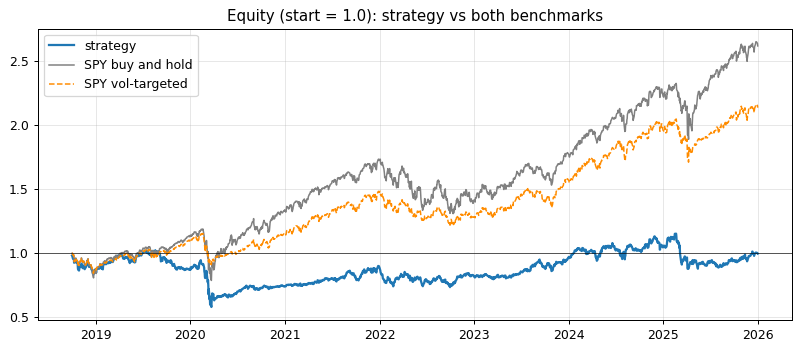

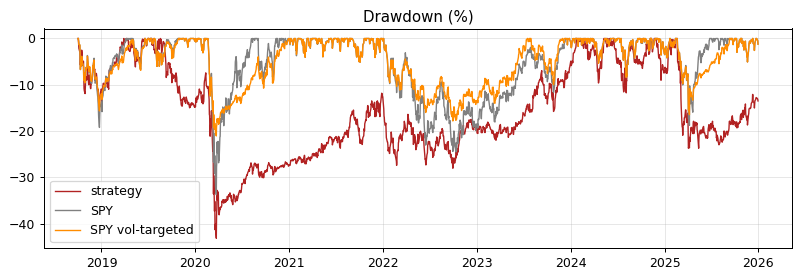

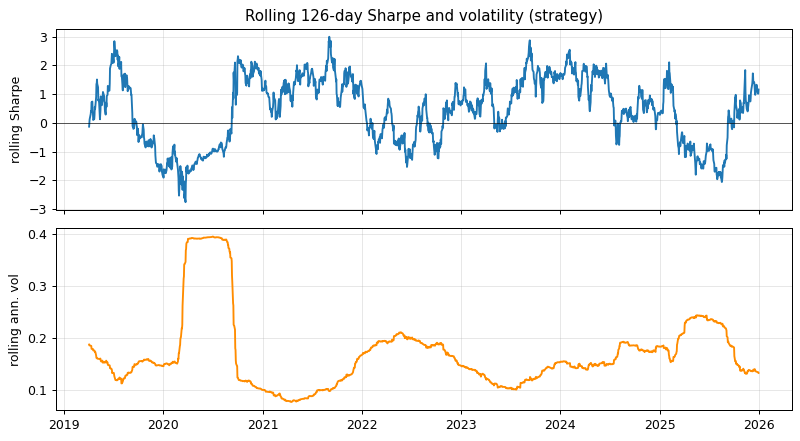

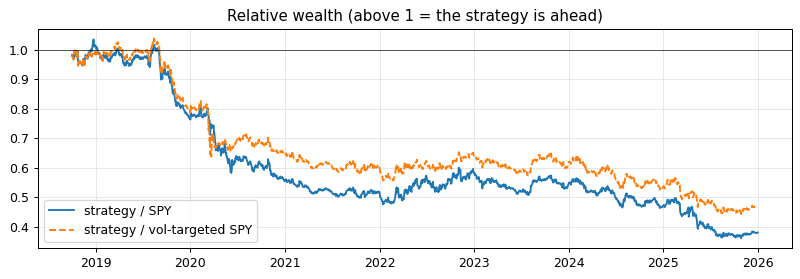

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot((1 + strat).cumprod(), label="strategy", lw=1.8)
ax.plot((1 + spy_ret).cumprod(), label="SPY buy and hold", lw=1.2, color="grey")
ax.plot((1 + vt_ret).cumprod(), label="SPY vol-targeted", lw=1.2, color="darkorange", ls="--")
ax.axhline(1.0, color="k", lw=0.5)
ax.set_title("Equity (start = 1.0): strategy vs both benchmarks")
ax.legend()
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(9, 3.2))
for name, r, c in (("strategy", strat, "firebrick"), ("SPY", spy_ret, "grey"), ("SPY vol-targeted", vt_ret, "darkorange")):
    ax.plot(drawdown_series(r) * 100, label=name, color=c, lw=1.1)
ax.set_title("Drawdown (%)")
ax.legend()
fig.tight_layout()
plt.show()
fig = plot_rolling_risk(strat, window=126, periods_per_year=ppy, title="Rolling 126-day Sharpe and volatility (strategy)")
plt.show()
rel = ((1 + strat).cumprod() / (1 + spy_ret).cumprod())
rel_vt = ((1 + strat).cumprod() / (1 + vt_ret).cumprod())
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(rel, label="strategy / SPY")
ax.plot(rel_vt, label="strategy / vol-targeted SPY", ls="--")
ax.axhline(1.0, color="k", lw=0.5)
ax.set_title("Relative wealth (above 1 = the strategy is ahead)")
ax.legend()
fig.tight_layout()
plt.show()

### 7.2 Calendar views, distribution, exposure, turnover and rolling beta

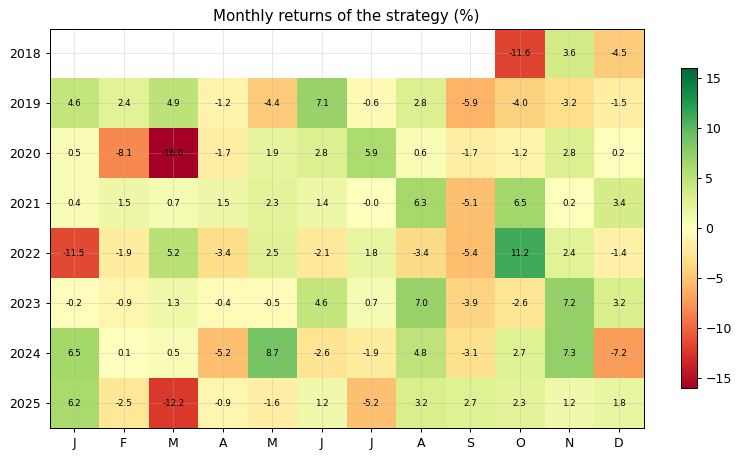

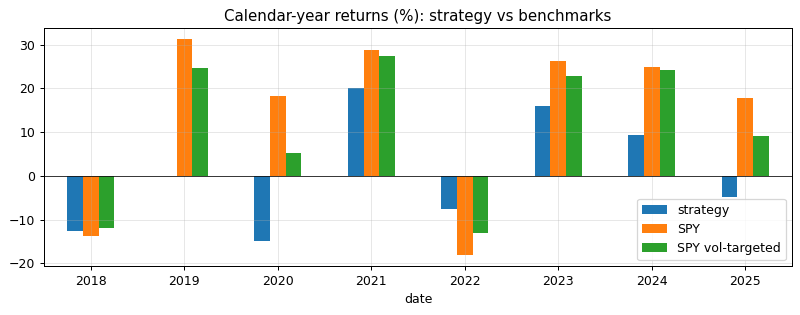

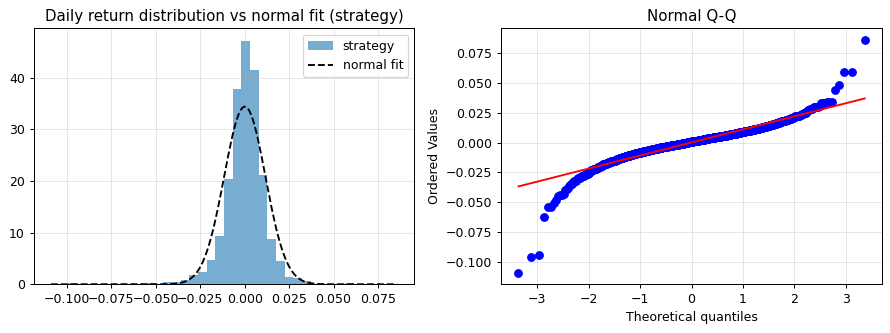

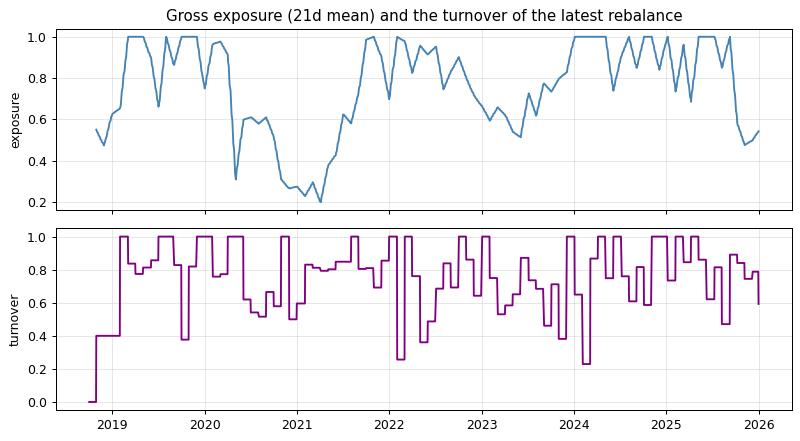

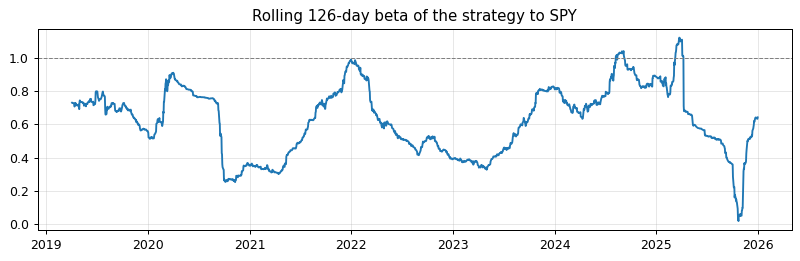

In [ ]:
fig = plot_monthly_heatmap(strat, title="Monthly returns of the strategy (%)")
plt.show()
yr = pd.DataFrame({"strategy": yearly_returns(strat), "SPY": yearly_returns(spy_ret), "SPY vol-targeted": yearly_returns(vt_ret)}) * 100
fig, ax = plt.subplots(figsize=(9, 3.6))
yr.plot.bar(ax=ax, rot=0)
ax.axhline(0.0, color="k", lw=0.6)
ax.set_title("Calendar-year returns (%): strategy vs benchmarks")
fig.tight_layout()
plt.show()
fig = plot_return_distribution(strat, title="Daily return distribution vs normal fit (strategy)")
plt.show()
turn = BT["weights"]["turnover"]
fig = plot_exposure_turnover(EQ["gross"].rolling(21).mean(), turn.reindex(EQ.index).ffill().fillna(0.0),
                             title="Gross exposure (21d mean) and the turnover of the latest rebalance")
plt.show()
beta_roll = strat.rolling(126).cov(spy_ret) / spy_ret.rolling(126).var()
fig, ax = plt.subplots(figsize=(9, 3.0))
ax.plot(beta_roll)
ax.axhline(1.0, color="grey", ls="--", lw=0.8)
ax.set_title("Rolling 126-day beta of the strategy to SPY")
fig.tight_layout()
plt.show()
RESULTS["years_beating_spy_share"] = float((yr["strategy"] > yr["SPY"]).mean())
RESULTS["years_beating_vt_share"] = float((yr["strategy"] > yr["SPY vol-targeted"]).mean())

## 8. Holdings: how concentrated, how often changed

Five names, rebalanced about monthly. The first chart is the share of the five-name book that is new at each rebalance (one minus the share of names carried over); the second is the gross exposure chosen by the volatility target.

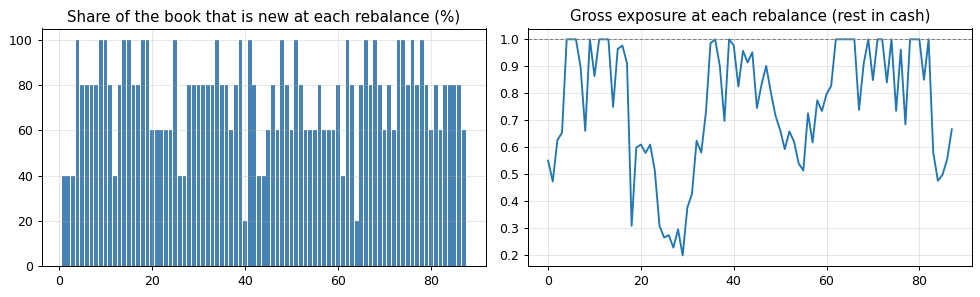

average share of the book replaced per rebalance: 74% | average gross exposure: 0.76


In [ ]:
w = BT["weights"]
held = w["holdings"].tolist()
new_share = [np.nan] + [1.0 - len(set(a) & set(b)) / max(len(b), 1) for a, b in zip(held[:-1], held[1:])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(range(len(new_share)), np.array(new_share) * 100, color="steelblue")
axes[0].set_title("Share of the book that is new at each rebalance (%)")
axes[1].plot(w["gross_exposure"].values)
axes[1].axhline(1.0, color="grey", ls="--", lw=0.8)
axes[1].set_title("Gross exposure at each rebalance (rest in cash)")
fig.tight_layout()
plt.show()
RESULTS["avg_new_share"] = float(np.nanmean(new_share))
print(f"average share of the book replaced per rebalance: {np.nanmean(new_share):.0%} | average gross exposure: {w['gross_exposure'].mean():.2f}")

## 9. The killing test: is the stock selection worth anything?

### 9.1 Alpha, information ratio and the Sharpe difference

The regression table in section 6 is the first test. Against SPY the question is whether the intercept is positive; against the vol-targeted SPY it is the same question after controlling for risk. A positive alpha needs a t-statistic around 2 or more to mean anything on a sample this short.

### 9.2 A placebo: random selection from the same names

Re-run the whole engine, same dates, same volatility target, same HRP step, same costs, with one change: instead of the 20 names with the highest momentum, take **20 names drawn at random from the names that can be ranked**. If momentum selection carries information, the real strategy should sit in the upper tail of this distribution. The draws are seeded.

100 random-selection runs in 188s


,cagr,sharpe,max_drawdown
mean,0.0460,0.0861,-0.3582
min,-0.0338,-0.3234,-0.4813
25%,0.0294,-0.0089,-0.3875
50%,0.0476,0.0932,-0.3530
75%,0.0644,0.1889,-0.3244
max,0.1266,0.5183,-0.2604


strategy Sharpe -0.15 sits at the 9th percentile of the placebo Sharpe distribution; share of placebos with a Sharpe at least as high: 0.91


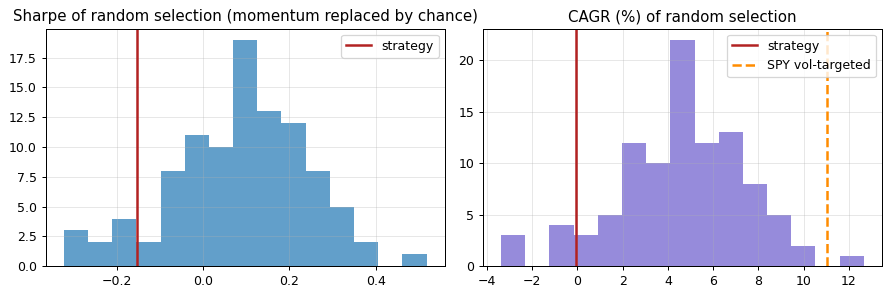

In [ ]:
rng = np.random.default_rng(int(PARAMS["random_seed"]))
n_pl = 8 if SYNTHETIC else int(PARAMS["n_placebo"])
t0 = time.time()
pl_rows = []
for k in range(n_pl):
    out = run_backtest(PRICES, MEMBER_SETS, dict(PARAMS, selection_mode="random_member"), rng=rng)
    eqp = out["equity"]
    rp = (eqp["equity"] / eqp["equity"].shift(1).fillna(float(PARAMS["capital"])) - 1.0)
    smp = performance_summary(rp, periods_per_year=ppy, risk_free=rf_ann)
    pl_rows.append({"cagr": calendar_cagr(rp), "sharpe": float(smp["sharpe"]), "max_drawdown": float(smp["max_drawdown"])})
pl = pd.DataFrame(pl_rows)
pctile = float((pl["sharpe"] < RESULTS["s_sharpe"]).mean() * 100)
print(f"{n_pl} random-selection runs in {time.time() - t0:.0f}s")
display(pl.describe().loc[["mean", "min", "25%", "50%", "75%", "max"]].round(4))
print(f"strategy Sharpe {RESULTS['s_sharpe']:.2f} sits at the {pctile:.0f}th percentile of the placebo Sharpe distribution; "
      f"share of placebos with a Sharpe at least as high: {(pl['sharpe'] >= RESULTS['s_sharpe']).mean():.2f}")
RESULTS.update({"placebo_n": int(n_pl), "placebo_pctile": pctile, "placebo_sharpe_mean": float(pl["sharpe"].mean()),
                "placebo_cagr_mean": float(pl["cagr"].mean()), "placebo_share_ge": float((pl["sharpe"] >= RESULTS["s_sharpe"]).mean()),
                "placebo_cagr_min": float(pl["cagr"].min()), "placebo_cagr_max": float(pl["cagr"].max())})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(pl["sharpe"], bins=15, alpha=0.7)
axes[0].axvline(RESULTS["s_sharpe"], color="firebrick", lw=2, label="strategy")
axes[0].set_title("Sharpe of random selection (momentum replaced by chance)")
axes[0].legend()
axes[1].hist(pl["cagr"] * 100, bins=15, alpha=0.7, color="slateblue")
axes[1].axvline(RESULTS["s_cagr"] * 100, color="firebrick", lw=2, label="strategy")
axes[1].axvline(RESULTS["vt_cagr"] * 100, color="darkorange", lw=2, ls="--", label="SPY vol-targeted")
axes[1].set_title("CAGR (%) of random selection")
axes[1].legend()
fig.tight_layout()
plt.show()

### 9.3 Sensitivity to the two signal choices

The lookback and the skip are the strategy's two free choices. The headline uses a lookback of 105 days and a skip of 21, fixed before any result was seen. The table re-runs the engine on a small grid of lookbacks and skips, with nothing else changed. It is shown so that the headline is read in context: it is neither the best nor an average case, and no cell of the grid is chosen as the headline.

cagr  sharpe
lookback skip                
42       0     0.0609  0.1688
         21    0.0098 -0.1048
84       0     0.0952  0.3627
         21    0.0404  0.0559
105      0     0.0502  0.1083
         21   -0.0004 -0.1538
147      0     0.0189 -0.0491
         21    0.0860  0.2940
210      0     0.0154 -0.0662
         21    0.0389  0.0579

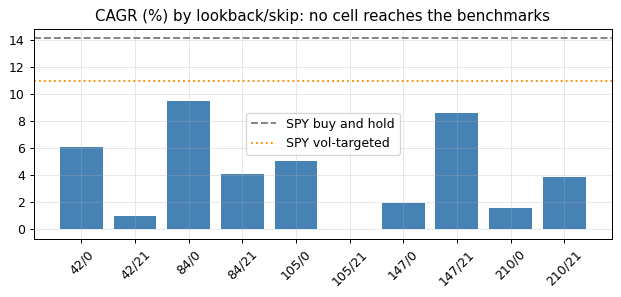

In [ ]:
rows = []
grid = [(42, 0), (42, 21), (84, 0), (84, 21), (105, 0), (105, 21), (147, 0), (147, 21), (210, 0), (210, 21)]
if SYNTHETIC:
    grid = [(84, 21), (105, 21)]
for lb, sk in grid:
    out = run_backtest(PRICES, MEMBER_SETS, dict(PARAMS, momentum_lookback=lb, momentum_skip_days=sk))
    e = out["equity"]["equity"]
    r = e / e.shift(1).fillna(float(PARAMS["capital"])) - 1.0
    rows.append({"lookback": lb, "skip": sk, "cagr": calendar_cagr(r),
                 "sharpe": float(performance_summary(r, periods_per_year=ppy, risk_free=rf_ann)["sharpe"])})
sens = pd.DataFrame(rows).set_index(["lookback", "skip"])
display(sens.round(4))
head = sens.loc[(int(PARAMS["momentum_lookback"]), int(PARAMS["momentum_skip_days"]))]
RESULTS.update({"sens_n": int(len(sens)), "sens_cagr_min": float(sens["cagr"].min()), "sens_cagr_max": float(sens["cagr"].max()),
                "sens_cagr_median": float(sens["cagr"].median()), "sens_n_beating_spy": int((sens["cagr"] > RESULTS["spy_cagr"]).sum()),
                "sens_headline_rank": int((sens["cagr"] < float(head["cagr"])).sum() + 1), "sens_table": sens.round(6).reset_index().to_dict("records")})
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(len(sens)), sens["cagr"] * 100, color="steelblue")
ax.axhline(RESULTS["spy_cagr"] * 100, color="grey", ls="--", label="SPY buy and hold")
ax.axhline(RESULTS["vt_cagr"] * 100, color="darkorange", ls=":", label="SPY vol-targeted")
ax.set_xticks(range(len(sens)), [f"{a}/{b}" for a, b in sens.index], rotation=45)
ax.set_title("CAGR (%) by lookback/skip: no cell reaches the benchmarks")
ax.legend()
fig.tight_layout()
plt.show()

## 10. Capital sweep and cost sensitivity

### 10.1 Capital sweep

The headline equity of 100,000 USD is an illustrative assumption, so the whole engine is re-run at six equity levels. **Only the initial equity changes**: names, signals, windows and the volatility target are identical and nothing is retuned. Two cost models are shown:

* **Headline (3 basis points of traded notional)**: proportional, so every ratio is the same at every level and the USD amounts scale linearly.
* **Per-order model**: the public broker per-share commission (0.0035 USD) with a minimum of 0.35 USD per order, plus 3 basis points of slippage. The minimum is a fixed fee, so it is a larger share of a small account.

The per-order model needs share prices; fractional shares are assumed (weights, not whole shares), as a simplification.

cost model: bps


capital,5000,10000,25000,50000,100000,250000
net_usd,-15.547,-31.095,-77.737,-155.473,-310.947,-777.367
net_return,-0.311,-0.311,-0.311,-0.311,-0.311,-0.311
cost_usd,86.705,173.410,433.524,867.048,1734.096,4335.241
cost_share,1.734,1.734,1.734,1.734,1.734,1.734
cagr,-0.043,-0.043,-0.043,-0.043,-0.043,-0.043
sharpe,-0.154,-0.154,-0.154,-0.154,-0.154,-0.154
max_drawdown,-43.113,-43.113,-43.113,-43.113,-43.113,-43.113


cost model: ibkr


capital,5000,10000,25000,50000,100000,250000
net_usd,-397.456,-494.164,-799.709,-1350.027,-2516.308,-6130.249
net_return,-7.949,-4.942,-3.199,-2.700,-2.516,-2.452
cost_usd,420.857,580.495,1072.598,1928.078,3696.821,9104.665
cost_share,8.417,5.805,4.290,3.856,3.697,3.642
cagr,-1.136,-0.697,-0.448,-0.377,-0.351,-0.342
sharpe,-0.214,-0.189,-0.176,-0.172,-0.171,-0.170
max_drawdown,-43.481,-43.343,-43.268,-43.247,-43.242,-43.241


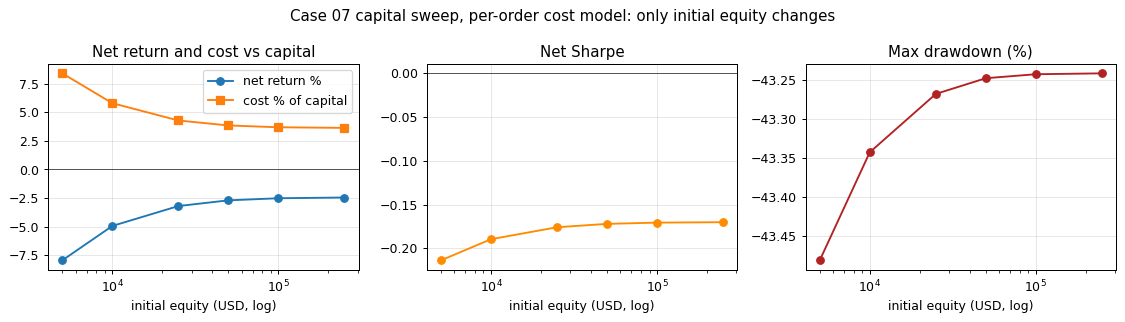

In [ ]:
def run_at_capital(cap_: float, model: str) -> Dict[str, float]:
    out = run_backtest(PRICES, MEMBER_SETS, dict(PARAMS, capital=float(cap_), cost_model=model))
    e = out["equity"]["equity"]
    r = e / e.shift(1).fillna(float(cap_)) - 1.0
    smc = performance_summary(r, periods_per_year=ppy, risk_free=rf_ann)
    total_cost = float(out["weights"]["cost"].sum())
    return {"net_usd": float(e.iloc[-1] - cap_), "net_return": float(e.iloc[-1] / cap_ - 1.0), "cost_usd": total_cost,
            "cost_share": total_cost / cap_, "cagr": calendar_cagr(r), "sharpe": float(smc["sharpe"]), "max_drawdown": float(smc["max_drawdown"])}


_caps = [5_000, 100_000] if SYNTHETIC else [5_000, 10_000, 25_000, 50_000, 100_000, 250_000]
sweeps = {m: capital_sweep(lambda c, m=m: run_at_capital(c, m), _caps) for m in ("bps", "ibkr")}
for m, df_ in sweeps.items():
    show = df_.copy()
    for col in ["net_return", "cost_share", "cagr", "max_drawdown"]:
        show[col] = (show[col] * 100).round(3)
    print(f"cost model: {m}")
    display(show.round(3).set_index("capital").T)
plot_capital_sweep(sweeps["ibkr"], title="Case 05 capital sweep, per-order cost model: only initial equity changes")
plt.show()
RESULTS["capital_sweep_bps"] = sweeps["bps"].round(6).to_dict("records")
RESULTS["capital_sweep_ibkr"] = sweeps["ibkr"].round(6).to_dict("records")
RESULTS["ibkr_cagr_small"] = float(sweeps["ibkr"]["cagr"].iloc[0])
RESULTS["ibkr_cagr_large"] = float(sweeps["ibkr"]["cagr"].iloc[-1])
RESULTS["sweep_bps_return_spread"] = float(sweeps["bps"]["net_return"].max() - sweeps["bps"]["net_return"].min())

### 10.2 Cost sensitivity (proportional model)

The proportional cost in basis points of traded notional is varied; everything else is identical.

In [ ]:
rows = []
for bps in (0.0, 3.0, 10.0, 25.0):
    out = run_backtest(PRICES, MEMBER_SETS, dict(PARAMS, transaction_cost_bps=bps))
    e = out["equity"]["equity"]
    r = e / e.shift(1).fillna(float(PARAMS["capital"])) - 1.0
    rows.append({"cost_bps": bps, "cagr": calendar_cagr(r), "sharpe": float(performance_summary(r, periods_per_year=ppy, risk_free=rf_ann)["sharpe"])})
cs = pd.DataFrame(rows).set_index("cost_bps")
display(cs.round(4))
RESULTS["cost_sweep"] = cs.round(6).reset_index().to_dict("records")
RESULTS["cagr_cost0"] = float(cs.loc[0.0, "cagr"])

,cagr,sharpe
cost_bps,,
0.0,0.0023,-0.1391
3.0,-0.0004,-0.1538
10.0,-0.0067,-0.1879
25.0,-0.0200,-0.2611


## 11. Interpretation

**Headline, at 100,000 USD of illustrative equity.** The strategy turns 100,000 USD into 99,689 USD, a CAGR of -0.04% with annualised volatility of 18.4%, a Sharpe ratio of -0.15 over a 4.5% cash rate and a maximum drawdown of -43.1%. Buy-and-hold SPY over the same dates ends at 261,433 USD (14.2% a year, Sharpe 0.54, maximum drawdown -33.7%); the volatility-targeted SPY ends at 213,357 USD (11.0% a year, Sharpe 0.50, maximum drawdown -21.0%). The strategy loses to both, on return and on risk-adjusted return.

**No edge, with numbers.** Regressed on SPY the strategy has a beta of 0.64 (R-squared 0.48), an annualised alpha of -8.1% and a t-statistic of -1.63; against the vol-targeted SPY the alpha is -8.4% (t = -1.65). The tracking error against SPY is 15.1% a year and the information ratio -0.90. The paired block bootstrap puts the Sharpe difference against SPY in [-1.13, -0.25] (the strategy has the higher Sharpe in 0% of resamples) and against the vol-targeted SPY in [-1.09, -0.20] (1%). The strategy beats SPY in 25% of calendar years and the vol-targeted SPY in 12%.

**The selection does not beat chance.** The random-selection placebo (same engine, names drawn at random from those that can be ranked) averages a CAGR of 4.6% and a Sharpe of 0.09 over 100 runs, with CAGRs from -3.4% to 12.7%. The strategy's Sharpe is at the 9th percentile of that distribution; 91% of the random runs did at least as well. On this sample momentum ranking is no better than picking five names at random from a good list (a low percentile is weak evidence of being worse, and no evidence of being better).

**The headline sits at the unfavourable end, and no choice of lookback rescues it.** Across the ten lookback and skip pairs of section 9.3 the CAGR ranges from -0.04% to 9.5% (median 4.0%); 0 of the 10 beat buy-and-hold SPY. The headline pair, fixed in advance, is number 1 from the bottom of the ten: it sits at the unfavourable end of a range that is itself far below the index, which is what noise around a zero edge looks like.

**Costs and capital do not explain it.** At the headline 3 basis points the strategy turns over about 74% of the book per rebalance (and replaces about 74% of the names); with zero cost the CAGR is 0.2%, still below both benchmarks. The capital sweep under the proportional model returns identical ratios at every level (largest difference in net return 3.2e-15); under the per-order model a small account pays more because of the fixed minimum, which moves the CAGR from -1.14% at 5,000 USD to -0.34% at 250,000 USD (section 10.1). The sign of the verdict does not depend on either.

**The comparison is optimistic.** On an average rebalance date 89% of the index members have a price (lowest 83%), but the gap is not random: 94% of the members that are still in the latest snapshot have one against only 58% of the members that were later removed, so the missing prices sit where the losers live. The membership table itself is made of only 13% later-removed names on average, and 95% of the rebalance dates fall after the public membership file's last snapshot, where membership is reconstructed from today's list and announced changes. A point-in-time version of this test would include stocks that failed after being selected; it can only look worse.

**Honest label.** No edge against the benchmark is the primary tag, and there is no secondary: the conclusion does not depend on the cost model, the capital or the exact selection rule, and the survivorship caveat strengthens it (the true result is likely worse).

## 12. The lesson

**Compare against the benchmark that takes the same risk, and against a random version of your own selection rule, before you read any single equity curve.** A momentum screen followed by a risk-parity step and a volatility target is a reasonable-sounding portfolio; its equity curve alone would not have said that it loses to holding the index with the same volatility target and to picking at random from the same list. And any test that draws on today's index members is a test on survivors.

## 13. What I would do differently

* **State the benchmark and the placebo before running anything.** Both take minutes and decide the verdict.
* **Use point-in-time data or say loudly that it is not.** A membership table and a price panel that include the delisted names (a paid, survivorship-bias-free dataset) are the minimum for a stock-selection claim.
* **Make early rebalances impossible to fill arbitrarily.** An unordered-set fallback chooses names in an arbitrary order; any fallback should be explicit, deterministic and visible in the results.
* **Pre-register the lookback.** The lookback and the skip are two choices that decide the signal; fix them before looking, and show the neighbours (a sensitivity), not only the chosen value.

## 14. How to improve it (ideas, not claims)

* Rank on a residual momentum (market-adjusted) or add a quality screen, and test each against the placebo.
* Replace the five-name book with a wider one (20 names) to cut idiosyncratic variance; the HRP step is more useful with more names.
* Add a transaction-cost-aware turnover limit (a no-trade band around the current weights).
* Evaluate on a point-in-time dataset that includes delisted names, and report the survivorship effect as the difference between the two runs.

## 15. FAQ

**Why compare against a volatility-targeted SPY?** The strategy holds less than full exposure much of the time (the average gross exposure is shown in section 6), so part of its lower return and lower drawdown is simply less risk. The scaled index has the same property for free.

**Why is the Sharpe computed over a 4.5% cash rate?** The constant overnight rate is both what idle cash earns in the backtest and what the Sharpe subtracts, so the figures are comparable between the strategy and the benchmarks. A lower cash rate would raise every Sharpe and not change the ordering.

**Is the result sensitive to the lookback of 105 days?** The number is (section 9.3 shows a spread of several CAGR points across ten lookback and skip pairs); the conclusion is not, because no pair reaches the index. The lookback is one of two free choices and neither was searched for the headline.

**Why not download the data in the notebook?** Vendor terms are unverified (see `DATA_LICENSING.md`); the reader obtains the data under their own terms.

**Does the failure reproduce in synthetic mode?** No. Synthetic stocks are driftless random walks with a common factor; the engine runs end to end and the placebo and the strategy are exchangeable by construction.

## 16. References

* Lopez de Prado, M. (2016). Building diversified portfolios that outperform out of sample. *Journal of Portfolio Management*, 42(4), 59-69.
* Jegadeesh, N. and Titman, S. (1993). Returns to buying winners and selling losers. *Journal of Finance*, 48, 65-91.
* Brown, S. J., Goetzmann, W., Ibbotson, R. and Ross, S. (1992). Survivorship bias in performance studies. *Review of Financial Studies*, 5, 553-580.
* Moreira, A. and Muir, T. (2017). Volatility-managed portfolios. *Journal of Finance*, 72, 1611-1644.
* Efron, B. and Tibshirani, R. (1993). *An Introduction to the Bootstrap.* Chapman and Hall.

## 17. Disclaimer

This notebook is educational. It documents a failed research experiment and is not financial advice or a recommendation to buy or sell any security. Equity investing involves substantial risk of loss. Past or hypothetical results do not predict future results, and this result is likely optimistic because of survivorship bias. The code is provided as is, without warranty.

In [ ]:
if os.environ.get("AUTOPSY_RESULTS_JSON"):
    Path(os.environ["AUTOPSY_RESULTS_JSON"]).write_text(json.dumps(RESULTS, indent=2, default=str))
print("done")

done
